# Frozen driving policy: traffic generalization

Evaluation of the saved 1,000-episode Expected SARSA, DQN and Dyna-DQN policies. All sensors stay on. No training occurs in this notebook. New traffic seeds test varied starting lanes, blocked passing lanes and repeated overtaking over 2.25, 5 and 9 km. A privileged oracle checks feasibility; a fixed maneuver provides a simple baseline.

The source Dyna policy performed no planning updates during training and has the same learned Q-network as DQN. Traffic vehicles hold their lanes; this study does not test cut-ins.

Rain and fog affect sensor measurements; weather does not alter tire/road friction in this simulation.

## What the evaluation shows

The policies solve the original controlled task but do not yet generalize reliably to more demanding driving. Every learned policy completed 20/20 control trips. With repeated traffic, SARSA completed 0/20 at 2.25 km, while DQN and Dyna completed 4/20. All three completed 0/20 at both 5 km and 9 km. The privileged oracle completed 13/20, 13/20 and 7/20 respectively; its failures were deadlines, not crashes.

SARSA crashed in all six varied-lead trials starting in the rightmost lane. Its failure replay shows repeated right commands and acceleration without trying left. DQN's longest trip reached 8,068.99 m in 360 seconds with ten overtakes and 129 recorded lane-index changes. It missed the deadline. This indicates excessive lateral and speed oscillation in that trajectory.

Dyna used zero planning updates in source training and matched DQN on every paired evaluation outcome. This is not evidence for a planning benefit. These results use one training seed, with all sensor power fixed on.

The next training experiment should mix ego starting lanes, lead distances and speeds, left/right blockers, and repeated encounters on shorter routes. Check impossible boundary commands and lane-change persistence, then repeat with independent training seeds and new final evaluation seeds. Establish reliable driving before adding the sensor-energy objective.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, HTML

here = Path.cwd()
root = next(p for p in (here, *here.parents) if (p / "runs/exploratory").is_dir())
output = root / "runs/exploratory/driving_generalization/frozen_1000ep_20261121"
metadata = json.loads((output / "metadata.json").read_text())
status = json.loads((output / "status.json").read_text())
print("Output:", output)
print("Status:", status)
print("Source checkpoint run:", Path(metadata["source_run"]).name)
print("Episodes per policy:", metadata["training_settings"]["episodes"])
print("Training seed:", metadata["training_seed"])
assert status["phase"] == "complete", "Wait until evaluation and replay export finish."
assert status["checkpoints_unchanged"]

Output: /Users/zac/Desktop/Reinforcment_Learning/final_project/experiments/artifacts/driving_generalization/frozen_1000ep_20261121
Status: {'phase': 'complete', 'done': 800, 'total': 800, 'wall_s': 1188.6240617920012, 'checkpoints_unchanged': True}
Source: /Users/zac/Desktop/Reinforcment_Learning/final_project/experiments/artifacts/driving_policy_v1/driving_500ep_20261121_103801_682209
Episodes per policy: 1000
Training seed: 42


## Completion and failure modes

Finish times are conditional on completing a trip. Compare crashes and deadline failures alongside time. These are new scenarios for one trained checkpoint per algorithm, not independent training repetitions.

policy,dqn,dyna_dqn,fixed_left_fast,oracle,sarsa
scenario,,,,,
blocked_left_1000m,15 / 20,15 / 20,0 / 20,20 / 20,20 / 20
blocked_right_1000m,5 / 20,5 / 20,20 / 20,20 / 20,16 / 20
control_1000m,20 / 20,20 / 20,20 / 20,20 / 20,20 / 20
repeated_2250m,4 / 20,4 / 20,0 / 20,13 / 20,0 / 20
repeated_5000m,0 / 20,0 / 20,0 / 20,13 / 20,0 / 20
repeated_9000m,0 / 20,0 / 20,0 / 20,7 / 20,0 / 20
varied_lead_1000m,16 / 20,16 / 20,13 / 20,20 / 20,14 / 20


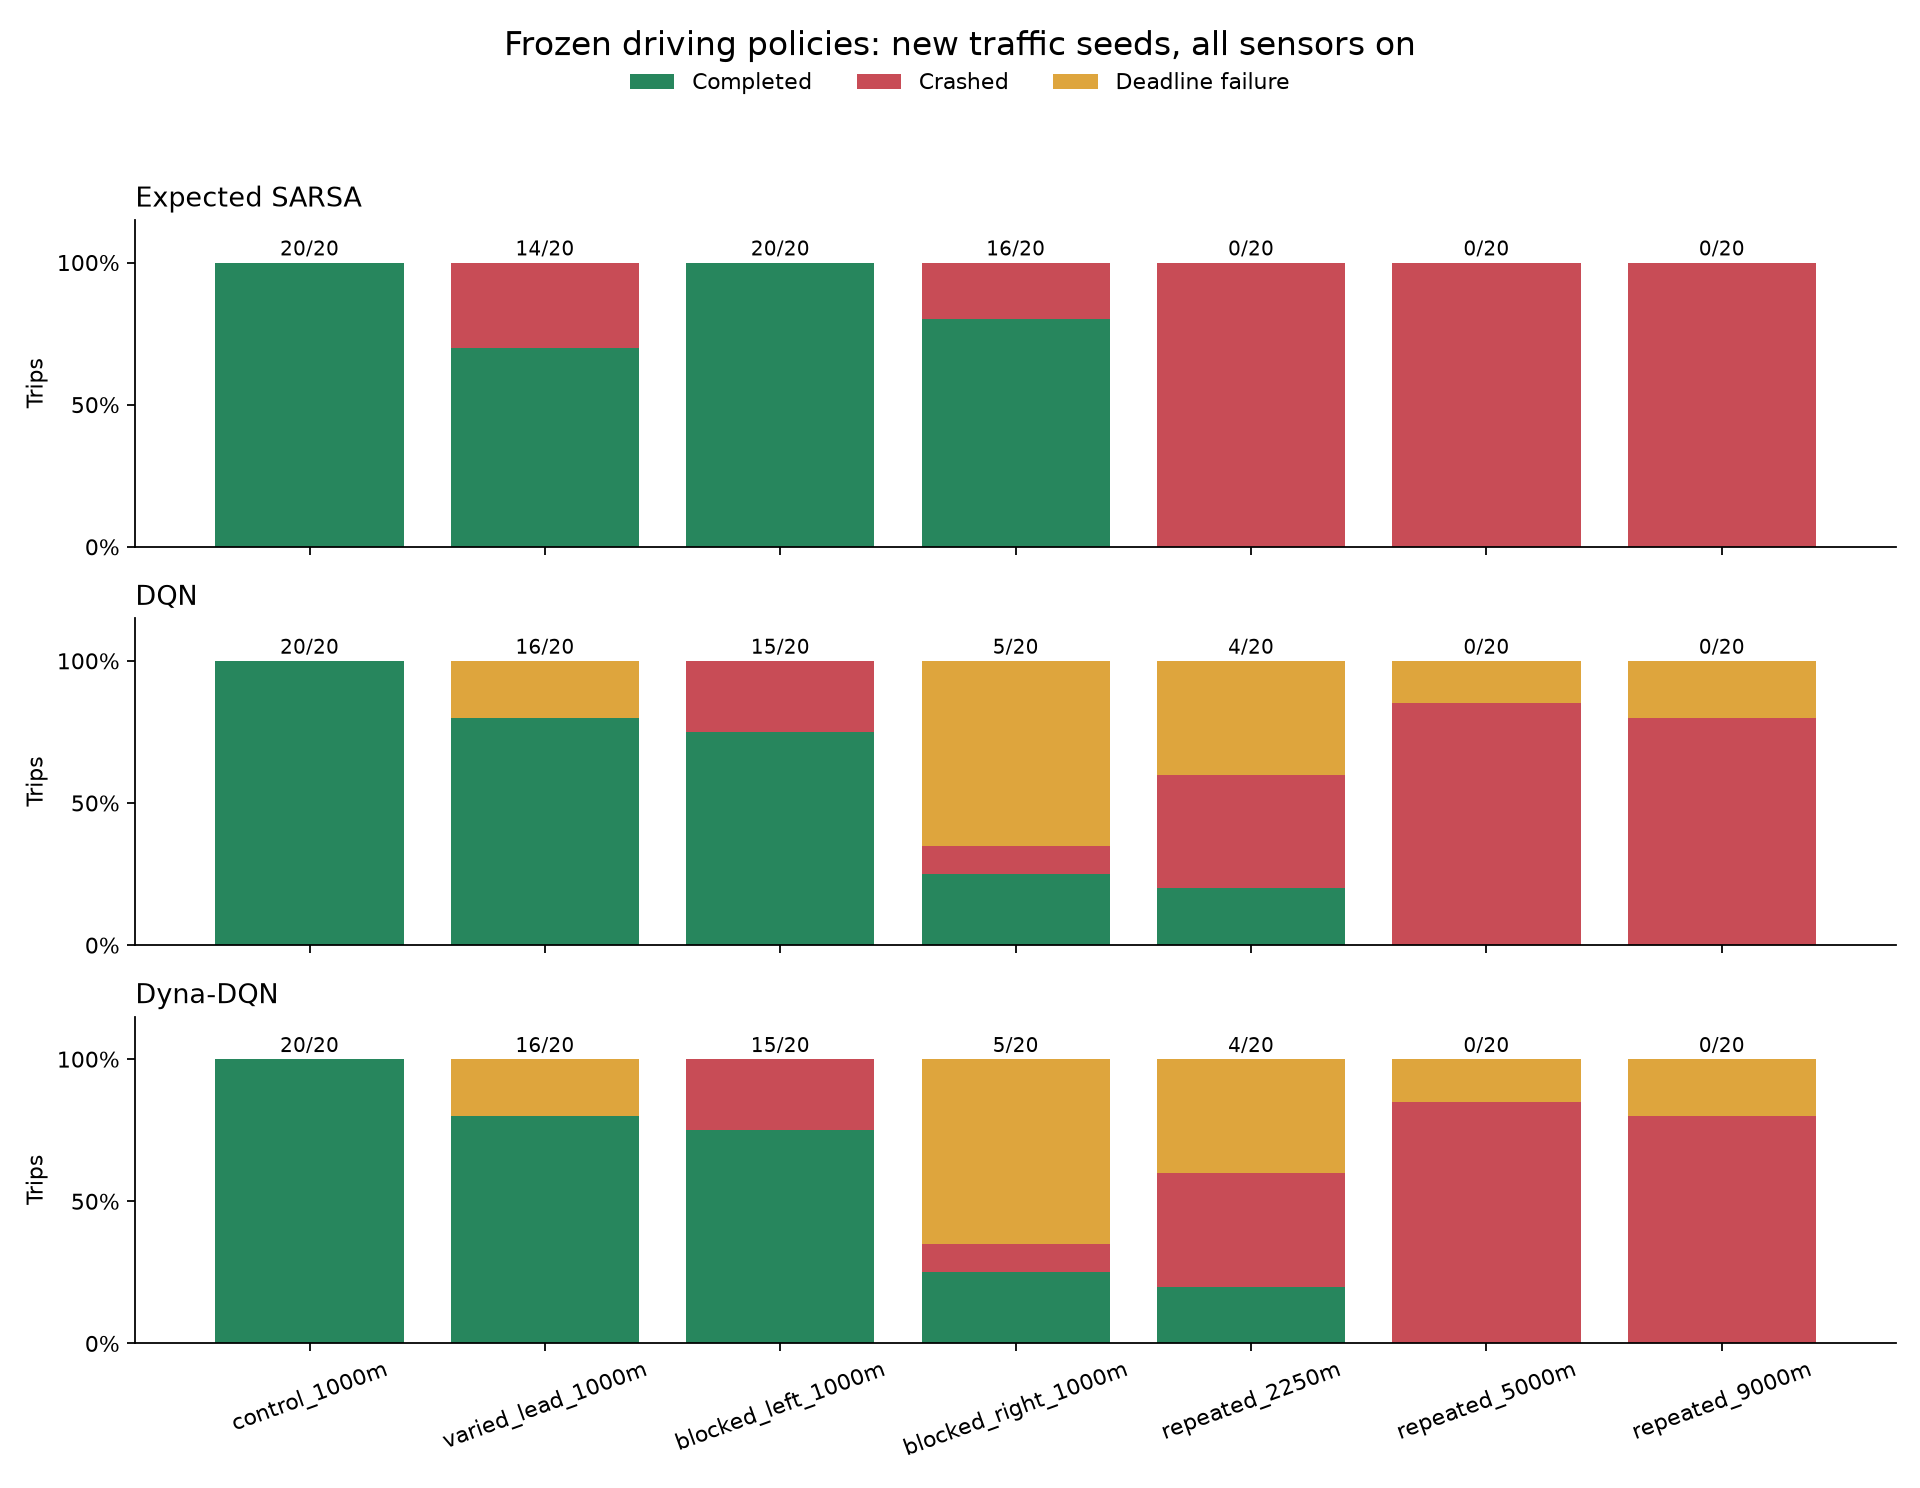

,scenario,weather,policy,trips,completions,crashes,deadline_failures,mean_finish_s,mean_overtakes,max_overtakes,completion_ci95_low,completion_ci95_high
0,control_1000m,clear,sarsa,20,20,0,0,34.300,1.00,1,0.839,1.000
1,control_1000m,clear,dqn,20,20,0,0,35.675,1.00,1,0.839,1.000
2,control_1000m,clear,dyna_dqn,20,20,0,0,35.675,1.00,1,0.839,1.000
3,control_1000m,clear,oracle,20,20,0,0,34.000,1.00,1,0.839,1.000
4,control_1000m,clear,fixed_left_fast,20,20,0,0,34.000,1.00,1,0.839,1.000
5,varied_lead_1000m,clear,sarsa,20,14,6,0,34.536,0.70,1,0.481,0.855
6,varied_lead_1000m,clear,dqn,20,16,0,4,35.281,0.80,1,0.584,0.919
7,varied_lead_1000m,clear,dyna_dqn,20,16,0,4,35.281,0.80,1,0.584,0.919
8,varied_lead_1000m,clear,oracle,20,20,0,0,34.000,1.00,1,0.839,1.000
9,varied_lead_1000m,clear,fixed_left_fast,20,13,7,0,34.000,0.65,1,0.433,0.819


In [2]:
evaluation = pd.read_csv(output / "evaluation.csv")
summary = pd.read_csv(output / "summary_with_intervals.csv")
clear = summary[summary.weather == "clear"].copy()
clear["completed / trips"] = clear.completions.astype(str) + " / " + clear.trips.astype(str)
display(clear.pivot(index="scenario", columns="policy", values="completed / trips"))
display(Image(filename=str(output / "evaluation_outcomes.png")))
display(summary[["scenario", "weather", "policy", "trips", "completions", "crashes",
                 "deadline_failures", "mean_finish_s", "mean_overtakes", "max_overtakes",
                 "completion_ci95_low", "completion_ci95_high"]].round(3))

## Paired feasibility and behavior

Oracle successes demonstrate feasibility for the corresponding traffic seed. Oracle failures do not prove a task impossible. The fixed driver uses ego telemetry to move left and accelerate; it ignores traffic. If it succeeds, that scenario admits a simple maneuver. Distinct overtakes are counted after encountering a vehicle ahead within 150 m and passing it by more than 10 m.

In [3]:
paired = pd.read_csv(output / "paired_oracle_summary.csv")
behavior = pd.read_csv(output / "behavior_summary.csv")
display(paired)
display(behavior[behavior.policy.isin(["sarsa", "dqn", "dyna_dqn"])].round(3))
# Failures in cases where the oracle completed the same seeded scenario.
paired_trials = pd.read_csv(output / "paired_oracle_trials.csv")
display(paired_trials[paired_trials.failed_when_oracle_completed][
    ["scenario", "weather", "policy", "seed", "crashed", "deadline_failure",
     "elapsed_s", "distance_m", "overtakes", "lane_changes"]].head(30))

,scenario,weather,policy,trips,oracle_completed,failures_despite_oracle_completion,completions_despite_oracle_failure
0,blocked_left_1000m,clear,dqn,20,20,5,0
1,blocked_left_1000m,clear,dyna_dqn,20,20,5,0
2,blocked_left_1000m,clear,sarsa,20,20,0,0
3,blocked_right_1000m,clear,dqn,20,20,15,0
4,blocked_right_1000m,clear,dyna_dqn,20,20,15,0
5,blocked_right_1000m,clear,sarsa,20,20,4,0
6,control_1000m,clear,dqn,20,20,0,0
7,control_1000m,clear,dyna_dqn,20,20,0,0
8,control_1000m,clear,sarsa,20,20,0,0
9,repeated_2250m,clear,dqn,20,13,10,1


,scenario,weather,policy,left_fraction,right_fraction,faster_fraction,slower_fraction,mean_lane_changes,mean_following_s,mean_overtakes,max_overtakes,mean_distance_m
0,blocked_left_1000m,clear,dqn,0.201,0.076,0.325,0.010,0.80,0.000,0.75,1,764.494
1,blocked_left_1000m,clear,dyna_dqn,0.201,0.076,0.325,0.010,0.80,0.000,0.75,1,764.494
4,blocked_left_1000m,clear,sarsa,0.000,0.489,0.506,0.002,1.00,0.000,1.00,1,1008.123
5,blocked_right_1000m,clear,dqn,0.171,0.209,0.147,0.257,13.70,5.815,0.65,2,935.701
6,blocked_right_1000m,clear,dyna_dqn,0.171,0.209,0.147,0.257,13.70,5.815,0.65,2,935.701
9,blocked_right_1000m,clear,sarsa,0.087,0.419,0.426,0.019,5.40,0.000,0.80,1,817.057
10,control_1000m,clear,dqn,0.133,0.073,0.320,0.088,4.75,0.658,1.00,1,1006.533
11,control_1000m,clear,dyna_dqn,0.133,0.073,0.320,0.088,4.75,0.658,1.00,1,1006.533
14,control_1000m,clear,sarsa,0.003,0.419,0.557,0.007,1.35,0.000,1.00,1,1009.688
15,repeated_2250m,clear,dqn,0.137,0.198,0.201,0.200,19.75,8.567,1.95,4,1741.163


,scenario,weather,policy,seed,crashed,deadline_failure,elapsed_s,distance_m,overtakes,lane_changes
0,blocked_left_1000m,clear,dqn,300000,True,False,1.0,24.658042,0,0
1,blocked_left_1000m,clear,dqn,300001,True,False,1.5,37.278419,0,0
8,blocked_left_1000m,clear,dqn,300008,True,False,1.5,39.903970,0,0
10,blocked_left_1000m,clear,dqn,300010,True,False,1.0,24.698106,0,0
12,blocked_left_1000m,clear,dqn,300012,True,False,1.0,24.658042,0,0
20,blocked_left_1000m,clear,dyna_dqn,300000,True,False,1.0,24.658042,0,0
21,blocked_left_1000m,clear,dyna_dqn,300001,True,False,1.5,37.278419,0,0
28,blocked_left_1000m,clear,dyna_dqn,300008,True,False,1.5,39.903970,0,0
30,blocked_left_1000m,clear,dyna_dqn,300010,True,False,1.0,24.698106,0,0
32,blocked_left_1000m,clear,dyna_dqn,300012,True,False,1.0,24.658042,0,0


In [4]:
# Identify failures tied to the ego starting lane.
lane_summary = pd.read_csv(output / "initial_lane_summary.csv")
display(lane_summary[(lane_summary.scenario == "varied_lead_1000m") &
                     lane_summary.policy.isin(["sarsa", "dqn", "dyna_dqn"])].round(3))

,scenario,weather,policy,initial_lane,trips,completions,crashes,deadline_failures,mean_lane_changes,left_fraction,right_fraction
40,varied_lead_1000m,clear,dqn,0,7,7,0,0,3.429,0.126,0.079
41,varied_lead_1000m,clear,dqn,1,7,7,0,0,5.857,0.130,0.124
42,varied_lead_1000m,clear,dqn,2,6,2,0,4,18.333,0.221,0.152
43,varied_lead_1000m,clear,dyna_dqn,0,7,7,0,0,3.429,0.126,0.079
44,varied_lead_1000m,clear,dyna_dqn,1,7,7,0,0,5.857,0.130,0.124
45,varied_lead_1000m,clear,dyna_dqn,2,6,2,0,4,18.333,0.221,0.152
52,varied_lead_1000m,clear,sarsa,0,7,7,0,0,2.000,0.000,0.403
53,varied_lead_1000m,clear,sarsa,1,7,7,0,0,1.286,0.002,0.420
54,varied_lead_1000m,clear,sarsa,2,6,0,6,0,0.000,0.000,0.841


## Replays and reproducibility

Each learned policy has a first failure and a longest-distance replay. Replay outcomes are checked against the evaluation table. The first failure is an illustrative case, not a substitute for the aggregate results. The output directory also contains every trip, scenario configuration, checkpoint hashes and protocol metadata.

In [5]:
print("Recorded evaluation trials:", len(evaluation))
print("To generate new replays and summary plots, run:")
print("python -m experiments.evaluate_driving_generalization")


Offline report: /Users/zac/Desktop/Reinforcment_Learning/final_project/experiments/artifacts/driving_generalization/frozen_1000ep_20261121/results.html
Evaluation trips: 800


To run a fresh evaluation from the project root, use a new output directory:

```bash
.venv/bin/python -m experiments.evaluate_driving_generalization --workers 3
.venv/bin/python -m experiments.summarize_driving_generalization PATH_TO_NEW_OUTPUT
```

This notebook only reads saved results. Introducing more difficult cases changes the task distribution; successful completion here does not establish safety or training-seed robustness.